# Buổi D4: Tìm núm vặn tốt nhất mà không tự lừa mình

**Hiện trường.** Chị Hạnh nhận một mô hình nhận dạng chữ số viết tay với cài đặt mặc định, đúng khoảng 98%. Đồng nghiệp bảo *"vặn núm cho tốt hơn đi"*. Có hai núm chính, mỗi núm vài chục giá trị, tức hàng trăm tổ hợp. Thử tay thì mệt, thử hết thì tốn, và **thử càng nhiều thì càng dễ tự lừa mình** (D1, chặng 5).

Buổi này dạy ba việc: **quét lưới** (`GridSearchCV`), **quét ngẫu nhiên** (`RandomizedSearchCV`) khi ngân sách có hạn, và **kiểm định chéo lồng nhau** để ước lượng điểm sau khi đã vặn núm một cách trung thực.

**Ẩn dụ:** vặn núm radio để tìm đài rõ nhất. Bạn dò, ghi nhớ chỗ rõ nhất, nhưng điểm "rõ nhất" bạn nghe lúc dò có phần do nhiễu may mắn.

**Lưu ý:** dữ liệu mẫu để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: mặc định và vặn núm khác nhau bao nhiêu? |
| Chặng 1 | Quét lưới: thử mọi tổ hợp |
| Chặng 2 | Quét ngẫu nhiên: cùng ngân sách, vì sao đôi khi tốt hơn? |
| Chặng 3 | Chọn khoảng quét: thang log và chạm biên |
| Chặng 4 | Vặn núm cũng quá khớp: kiểm định chéo lồng nhau |
| Chặng 5 | Bao nhiêu là đủ? Dừng đúng lúc |

## Chặng 0: Thấy ngay, mặc định và vặn núm

**Câu hỏi:** vặn núm giúp được bao nhiêu?

Mô hình: **SVM** (đã học ở C6) với hai núm chính: **C** (mức nghiêm khắc với lỗi) và **gamma** (độ "cong" của ranh giới). Ta so cài đặt mặc định với cài đặt sau khi tìm.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
default = make_pipeline(StandardScaler(), SVC()).fit(X_train, y_train)
print("default SVC test score:", round(default.score(X_test, y_test), 4))

default SVC test score: 0.9833


**Giải thích từng dòng**

- `load_digits(return_X_y=True)`: 1797 ảnh chữ số 8×8 (đã dùng ở C7).
- `make_pipeline(StandardScaler(), SVC())`: SVM sau chuẩn hóa (cần thiết, đã học ở C6). Không đặt tham số nào nên dùng mặc định `C=1`, `gamma='scale'`.

## Chặng 1: Quét lưới, thử mọi tổ hợp

**Câu hỏi:** tổ hợp (C, gamma) nào tốt nhất?

Đời thường: bảng có 5 hàng (C) × 5 cột (gamma) = 25 ô; ta thử từng ô. Mỗi ô được chấm bằng kiểm định chéo 5 phần, vậy tổng cộng **25 × 5 = 125 lần học**. `GridSearchCV` làm giúp và ghi lại mọi kết quả.

In [3]:
pipe = make_pipeline(StandardScaler(), SVC())
grid = {"svc__C": [0.1, 1, 10, 100, 1000], "svc__gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
cv = StratifiedKFold(5, shuffle=True, random_state=0)
gs = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1).fit(X_train, y_train)
print("best params:", gs.best_params_)
print("best CV score:", round(gs.best_score_, 4), "| test score:", round(gs.score(X_test, y_test), 4))
print("number of fits:", len(gs.cv_results_["params"]) * 5)

best params: {'svc__C': 10, 'svc__gamma': 0.01}
best CV score: 0.9817 | test score: 0.9815
number of fits: 125


**Giải thích từng dòng**

- `'svc__C': [...]`: tên tham số theo dạng `tênbước__tênthamsố` (hai gạch dưới). Tên bước là tên lớp viết thường (`svc`). Đây là cách trỏ vào tham số **bên trong** pipeline (đã gặp ở C9).
- `1e-4`: ghi số khoa học: 1×10⁻⁴ = 0,0001. Các núm kiểu này nên quét theo **bậc 10** (gấp 10 lần) chứ không theo bước đều.
- `GridSearchCV(pipe, grid, cv=cv, n_jobs=-1)`: thử mọi tổ hợp của `grid`, chấm bằng `cv`. `n_jobs=-1` dùng mọi lõi CPU để chạy song song.
- `.fit(X_train, y_train)`: chạy tìm trên **phần học**, tập thi chưa đụng.
- `gs.best_params_ / gs.best_score_`: tổ hợp tốt nhất và điểm kiểm định chéo của nó.
- `gs.score(X_test, y_test)`: sau khi chọn xong, `GridSearchCV` học lại mô hình tốt nhất trên cả phần học và ta chấm một lần trên tập thi.

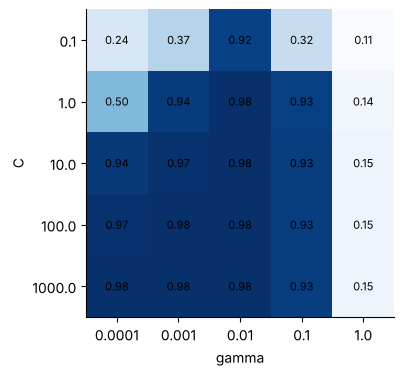

In [4]:
res = pd.DataFrame(gs.cv_results_)
heat = res.pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
fig, ax = plt.subplots()
im = ax.imshow(heat.values, cmap="Blues", vmin=heat.values.min(), vmax=heat.values.max())
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("gamma"); ax.set_ylabel("C"); plt.show()

**Giải thích từng dòng**

- `pd.DataFrame(gs.cv_results_)`: `cv_results_` chứa kết quả **mọi** tổ hợp; biến thành bảng để xem.
- `res.pivot_table(index=..., columns=..., values='mean_test_score')`: xoay thành bảng: hàng là C, cột là gamma, giá trị là điểm trung bình.
- `ax.text(j, i, ...)`: ghi số vào từng ô cho dễ đọc.

**Cách đọc.**
- **Con số:** mặc định đạt **98,33%** trên tập thi; sau khi quét lưới (tốt nhất `{'svc__C': 10, 'svc__gamma': 0.01}`) đạt **98,15%**. Điểm kiểm định chéo tốt nhất là **98,17%**.
- **Bức tranh:** bản đồ nhiệt cho thấy **vùng sáng** (nhiều tổ hợp tốt), không chỉ một điểm. Vùng tối là gamma quá lớn (quá cong, học vẹt) hoặc quá nhỏ.
- **Nói thật:** tập thi có 540 ảnh nên chênh lệch giữa mặc định và bản vặn núm chỉ khoảng **1** ảnh, nằm trong sai số. Ở bài này vặn núm **không đem lại lợi ích rõ**.
- **Thực tế:** vặn núm giúp ít khi mô hình mặc định đã tốt. Nếu mặc định đã gần trần, lợi ích của việc tìm là nhỏ.
- **Câu hỏi tiếp:** 2 núm với 5 giá trị là 25 ô. Với 5 núm thì sao?

**Mang về chặng 1:** quét lưới thử mọi ô; tổng số lần học = số tổ hợp × số phần kiểm định chéo.

## Chặng 2: Quét ngẫu nhiên, cùng ngân sách

**Câu hỏi:** với 5 núm, mỗi núm 5 giá trị là 3125 ô × 5 = 15 625 lần học. Có cách nào rẻ hơn?

Đời thường: tìm quán cà phê ngon trong thành phố. Duyệt từng con hẻm theo lưới thì tốn; **bốc ngẫu nhiên 20 quán** thường đã gặp quán khá ngon. Lý do: thường chỉ **một vài núm thật sự quan trọng**, và lưới lặp lại cùng vài giá trị của núm quan trọng, còn ngẫu nhiên thử **giá trị mới** ở mỗi lần.

`RandomizedSearchCV` bốc ngẫu nhiên `n_iter` tổ hợp từ các **phân phối**. Ta cho cùng ngân sách 25 tổ hợp như lưới ở chặng 1.

In [5]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
dist = {"svc__C": loguniform(0.1, 1000), "svc__gamma": loguniform(1e-4, 1)}
rs = RandomizedSearchCV(pipe, dist, n_iter=25, cv=cv, n_jobs=-1, random_state=0).fit(X_train, y_train)
print("random search best:", {k: round(float(v), 5) for k, v in rs.best_params_.items()})
print("best CV score:", round(rs.best_score_, 4), "| test score:", round(rs.score(X_test, y_test), 4))
print("grid for comparison: CV", round(gs.best_score_, 4), "| test", round(gs.score(X_test, y_test), 4))

random search best: {'svc__C': 25.76639, 'svc__gamma': 0.01512}
best CV score: 0.9833 | test score: 0.9815
grid for comparison: CV 0.9817 | test 0.9815


**Giải thích từng dòng**

- `from scipy.stats import loguniform`: mượn phân phối từ thư viện scipy.
- `loguniform(0.1, 1000)`: bốc số ngẫu nhiên sao cho **mỗi bậc 10 có xác suất như nhau** (0,1 đến 1, 1 đến 10, ... đều ngang nhau). Hợp với núm cần quét theo bậc 10.
- `RandomizedSearchCV(pipe, dist, n_iter=25, ...)`: giống `GridSearchCV` nhưng nhận phân phối, và `n_iter` là **số tổ hợp thử** (ngân sách).
- `random_state=0`: hạt giống của việc bốc ngẫu nhiên, để ai chạy cũng ra cùng tập tổ hợp.

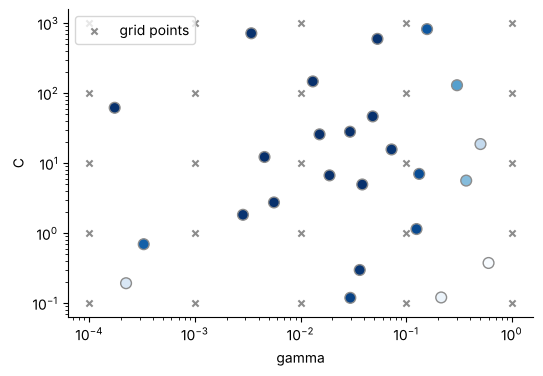

In [6]:
r = pd.DataFrame(rs.cv_results_)
fig, ax = plt.subplots()
ax.scatter(r["param_svc__gamma"].astype(float), r["param_svc__C"].astype(float), c=r["mean_test_score"], cmap="Blues", edgecolor=GRAY, s=60)
gx, gy = np.meshgrid(grid["svc__gamma"], grid["svc__C"])
ax.scatter(gx.ravel(), gy.ravel(), marker="x", color=GRAY, s=20, label="grid points")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.legend()
plt.show()

**Giải thích từng dòng**

- `c=r['mean_test_score']`: tô màu mỗi điểm theo điểm kiểm định chéo (đậm là cao).
- `ax.set_xscale('log')`: thang log cho trục để các bậc 10 cách đều nhau.
- `np.meshgrid(...)`: tạo các điểm giao của lưới để đánh dấu bằng dấu `x`. Đây là phần trang trí.

**Cách đọc.**
- **Con số:** quét ngẫu nhiên: điểm kiểm định chéo **98,33%**, thi **98,15%**. Quét lưới: **98,17%** và **98,15%**.
- **Bức tranh:** cùng 25 lần thử, hai cách cho kết quả **gần nhau** ở đây (2 núm, bài toán dễ). Cái hay của ngẫu nhiên là ở dữ liệu nhiều núm, nơi lưới nổ tung số tổ hợp còn ngẫu nhiên giữ nguyên ngân sách.
- **Quy tắc:** ít núm (1 đến 2) thì lưới; nhiều núm hoặc ngân sách hạn chế thì ngẫu nhiên.

**Mang về chặng 2:** quét ngẫu nhiên cho bạn kiểm soát ngân sách; nó thử nhiều giá trị khác nhau cho từng núm hơn lưới.

## Chặng 3: Chọn khoảng quét, thang log và chạm biên

**Câu hỏi:** nếu tổ hợp tốt nhất nằm **sát mép** khoảng quét thì sao?

Đời thường: bạn dò radio từ tần số 88 đến 108, nhưng đài rõ nhất kêu to nhất **ở 108**. Rất có thể còn đài còn rõ hơn ở 109. Khoảng quét phải **bao quanh** đỉnh, không chạm mép.

Ta kiểm tra: lưới của chặng 1 có chạm biên không, rồi quét thêm một lưới **mở rộng ở phía chạm biên** nếu cần.

In [7]:
best = gs.best_params_
edges = {k: (best[k] == min(v), best[k] == max(v)) for k, v in grid.items()}
print("best:", best)
print("(at lower edge, at upper edge):", edges)

best: {'svc__C': 10, 'svc__gamma': 0.01}
(at lower edge, at upper edge): {'svc__C': (False, False), 'svc__gamma': (False, False)}


**Giải thích từng dòng**

- `best[k] == min(v)`: kiểm tra giá trị tốt nhất có bằng giá trị nhỏ nhất trong khoảng quét không.
- `{k: (...) for k, v in grid.items()}`: duyệt từng núm, lập từ điển tên núm → (chạm mép dưới?, chạm mép trên?). Đây là cú pháp 'từ điển rút gọn'.

**Cách đọc.** Nếu một núm hiện `True` ở mép nào, đỉnh có thể nằm ngoài khoảng quét; hãy **mở rộng** về phía đó rồi quét lại. Kết quả ở trên cho `{'svc__C': (False, False), 'svc__gamma': (False, False)}`. Nếu toàn `False`, khoảng quét đã bao quanh đỉnh.

**Mẹo chọn khoảng ban đầu:**
- Núm quét theo **bậc 10** (C, gamma, alpha của Ridge...): thang log.
- Núm số nguyên nhỏ (k láng giềng, độ sâu cây): quét đều 1 đến 30.
- Quét thô trước (ít giá trị, khoảng rộng), thu hẹp quanh vùng sáng, quét tinh sau.

**Mang về chặng 3:** kiểm tra chạm biên; nếu chạm thì mở rộng khoảng quét về phía đó.

## Chặng 4: Vặn núm cũng quá khớp, kiểm định chéo lồng nhau

**Câu hỏi:** điểm kiểm định chéo **tốt nhất** của quét núm có đáng tin như một ước lượng cho dữ liệu mới không?

Không hẳn. Ta đã **chọn** tổ hợp có điểm cao nhất, và (D1, chặng 5) điểm cao nhất luôn có một phần là may mắn. Cách ước lượng trung thực: **kiểm định chéo lồng nhau** (*nested CV*). Vòng **ngoài** chia dữ liệu thành học/thi; trong mỗi vòng ngoài, vòng **trong** quét núm chỉ trên phần học của vòng đó; rồi chấm trên phần thi vòng ngoài mà vòng trong **chưa từng thấy**.

Để thấy tác dụng rõ, ta dùng **một phần nhỏ** dữ liệu (300 ảnh) và một lưới lớn hơn.

In [8]:
from sklearn.model_selection import cross_val_score
rng = np.random.RandomState(0)
idx = rng.choice(len(X), 300, replace=False)
Xs, ys = X[idx], y[idx]
big_grid = {"svc__C": np.logspace(-2, 3, 8), "svc__gamma": np.logspace(-5, 0, 8)}
inner = StratifiedKFold(3, shuffle=True, random_state=1)
outer = StratifiedKFold(5, shuffle=True, random_state=2)
search = GridSearchCV(pipe, big_grid, cv=inner, n_jobs=-1)
nested = cross_val_score(search, Xs, ys, cv=outer)
naive = search.fit(Xs, ys).best_score_
print("naive (best inner CV score):", round(naive, 4))
print("nested CV (honest):", round(nested.mean(), 4), "+/-", round(nested.std(), 4))

naive (best inner CV score): 0.9567
nested CV (honest): 0.95 +/- 0.0211


**Giải thích từng dòng**

- `rng.choice(len(X), 300, replace=False)`: chọn ngẫu nhiên 300 ảnh để mô phỏng dữ liệu ít.
- `np.logspace(-2, 3, 8)`: 8 số cách đều **theo thang log** từ 10⁻² đến 10³.
- `GridSearchCV(pipe, big_grid, cv=inner, ...)`: vòng **trong**: bộ tìm núm với 3 phần.
- `cross_val_score(search, Xs, ys, cv=outer)`: đưa **cả bộ tìm** vào kiểm định chéo vòng **ngoài**. Mỗi vòng ngoài, bộ tìm học núm trên phần học rồi bị chấm trên phần thi chưa thấy.
- `search.fit(Xs, ys).best_score_`: cách làm 'ngây thơ': quét trên toàn bộ rồi lấy điểm tốt nhất làm kết quả.

**Cách đọc.**
- **Con số:** điểm "ngây thơ" **95,67%**; điểm lồng nhau trung thực **95,00%** (± 2,11%). Chênh lệch **0,67** điểm phần trăm.
- **Bức tranh:** điểm tốt nhất của quét núm thường **lạc quan hơn** một chút so với điểm trung thực, và mức lạc quan **tăng khi dữ liệu ít và lưới lớn**. Kiểm định chéo lồng nhau đo đúng cả quy trình "chọn núm rồi dùng".
- **Lưu ý:** chênh lệch có thể nhỏ trong một lần chạy cụ thể; điều không đổi là nguyên tắc: nếu bạn dùng điểm để chọn thì điểm đó không còn là ước lượng trung thực.
- **Thực tế:** kiểm định chéo lồng nhau tốn thời gian (số vòng ngoài × số vòng trong × số tổ hợp). Chỉ cần khi **so sánh quy trình** hoặc báo cáo cuối với dữ liệu ít; còn thông thường, **tập thi niêm phong** giữ nguyên vai trò chấm cuối.

**Mang về chặng 4:** điểm tốt nhất sau khi vặn núm là lạc quan; đo trung thực bằng kiểm định chéo lồng nhau hoặc tập thi niêm phong.

## Chặng 5: Bao nhiêu là đủ, dừng đúng lúc

**Câu hỏi:** khi nào thôi vặn núm?

Ta xem điểm kiểm định chéo **tốt nhất tới lúc này** theo số tổ hợp đã thử (quét ngẫu nhiên, 60 lần).

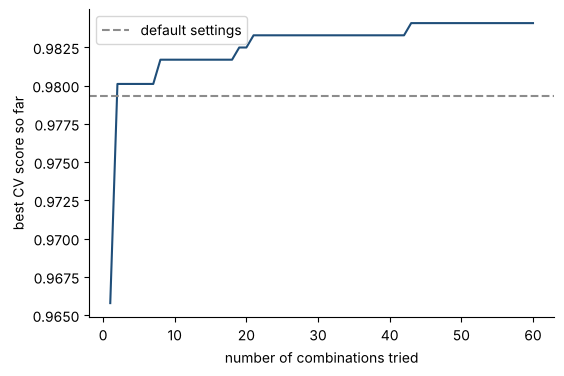

In [9]:
rs60 = RandomizedSearchCV(pipe, dist, n_iter=60, cv=cv, n_jobs=-1, random_state=3).fit(X_train, y_train)
scores = rs60.cv_results_["mean_test_score"]
best_so_far = np.maximum.accumulate(scores)
fig, ax = plt.subplots()
ax.plot(range(1, 61), best_so_far, color=BLUE)
ax.axhline(default_cv := cross_val_score(pipe, X_train, y_train, cv=cv).mean(), color=GRAY, linestyle="--", label="default settings")
ax.set_xlabel("number of combinations tried"); ax.set_ylabel("best CV score so far"); ax.legend()
plt.show()

**Giải thích từng dòng**

- `np.maximum.accumulate(scores)`: điểm cao nhất **tính đến từng lần thử**: đường chỉ có thể đi lên hoặc đi ngang.
- `default_cv := ...`: gán biến ngay trong biểu thức (dấu `:=`): tính điểm kiểm định chéo của cài đặt mặc định để vẽ thành vạch ngang.

**Cách đọc.**
- **Con số:** sau 60 lần thử điểm kiểm định chéo tốt nhất **98,41%**; cài đặt mặc định **97,93%**. Đạt **98,17%** sau 10 lần thử.
- **Bức tranh:** đường cong tăng nhanh lúc đầu rồi gần như đi ngang: **lợi ích giảm dần**. Dừng khi đường đã phẳng, hoặc khi mức cải thiện nhỏ hơn **độ dao động** của chính điểm (D1).
- **Phán quyết:** mỗi giờ vặn núm nên được so với một giờ làm việc khác: **làm sạch dữ liệu, thêm cột có ý nghĩa, sửa nhãn** thường đem lại nhiều hơn. Vặn núm là bước **cuối**, không phải bước đầu.

**Mang về chặng 5:** dừng khi đường điểm phẳng; vặn núm là bước tinh chỉnh cuối cùng chứ không phải cách cứu một mô hình dở.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Vặn núm giúp ít khi mặc định đã tốt. |
| 1 | `GridSearchCV` thử mọi ô; số lần học = số tổ hợp × số phần. |
| 2 | `RandomizedSearchCV` kiểm soát ngân sách, thử nhiều giá trị khác nhau hơn. |
| 3 | Quét theo thang log; nếu đỉnh chạm biên thì mở rộng. |
| 4 | Điểm tốt nhất sau khi tìm là lạc quan; dùng kiểm định chéo lồng nhau hoặc tập thi niêm phong. |
| 5 | Dừng khi đường điểm phẳng; vặn núm là bước cuối. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Vặn núm radio | tìm siêu tham số | `GridSearchCV`, `RandomizedSearchCV` |
| Bảng ô × ô, thử từng ô | quét lưới | `GridSearchCV(pipe, grid)` |
| Bốc ngẫu nhiên N ô | quét ngẫu nhiên | `RandomizedSearchCV(..., n_iter=N)` |
| Mỗi bậc 10 đều như nhau | phân phối log-đều | `loguniform`, `np.logspace` |
| Tên núm trong dây chuyền | tên tham số lồng nhau | `svc__C` |
| Điểm cao nhất lúc dò đài | điểm tốt nhất (lạc quan) | `best_score_` |
| Thi thử cả quy trình dò đài | kiểm định chéo lồng nhau | `cross_val_score(GridSearchCV(...))` |

**Thử thách tự làm**

1. Thêm `kernel` ("rbf", "linear") vào lưới ở chặng 1. Kernel nào thắng trên chữ số? Số lần học tăng bao nhiêu?
2. Chạy `RandomizedSearchCV` với `random_state` khác nhau 5 lần (chặng 2). Điểm tốt nhất dao động bao nhiêu?
3. Ở chặng 4, tăng dữ liệu từ 300 lên 1000 ảnh. Chênh lệch giữa điểm ngây thơ và lồng nhau co lại hay nở ra?
4. Dùng `scoring="f1_macro"` thay mặc định trong `GridSearchCV`. Tổ hợp tốt nhất có đổi không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Dựng được `GridSearchCV` trên một pipeline với tên tham số `bước__tên`.
- [ ] Đọc `cv_results_` và vẽ bản đồ nhiệt của hai núm.
- [ ] Giải thích khi nào chọn quét ngẫu nhiên.
- [ ] Kiểm tra chạm biên và mở rộng khoảng quét.
- [ ] Giải thích vì sao điểm tốt nhất sau khi tìm là lạc quan.

## Phần thưởng (Tip pro): Chấm điểm bằng thước đo đúng bài toán


Mặc định `GridSearchCV` chấm bằng độ đúng (accuracy). Nếu nhóm hiếm và bạn quan tâm recall, hãy đặt `scoring="recall"` hoặc `scoring="f1"` (hoặc `"average_precision"`); với hồi quy, `"neg_mean_absolute_error"` (có dấu âm vì sklearn luôn coi **điểm càng cao càng tốt**). Chọn thước đo **trước** khi quét, theo giá của lỗi, đúng như đã làm ở C9.